# Carrying a PD curve to a new year: scaled PDs, scaled likelihood ratio and QMM

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (a PD by grade and the long-run average)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- say what a rating model is as a joint distribution of grade and default, and check Tasche's identities between the PD curve, the rating profile and the default profile on a real model;
- smooth a PD curve with quasi moment matching (QMM) and say why a curve with zeros cannot be used as it is;
- carry a PD curve from an estimation year to a forecast year by the four approaches that know the forecast profile and PD: invariant default profile, invariant accuracy ratio, scaled PDs, scaled likelihood ratio, each with its constants printed;
- say what the cases where only the PD, or only the profile, is known add, and why carrying the old curve unchanged is the costliest choice;
- read the chi-square test of the implied default profile, and price the choice in IRB risk weight.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import pd_curve as pc
from riskvalidation.regulatory import capital_requirement

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed files of case C05, the calibration of a PD curve on the S&P corporate ratings of Tasche (2013) (licence class `derived-only`: the artifact holds the rating profile, the default rate by grade and the results, never the grade counts, so no notebook recomputes anything that needs the counts; https://doi.org/10.21314/jcr.2013.169):

- `data/derived/C05/sp-2010.json` and `data/derived/C05/sp-2011.json`: the 2009 estimation model (`profile0`, `default_rate0`, `default_profile0`, `pd0`, `ar0`) and the forecast year's profile and PD (`profile1`, `pd1`) over 17 grades from AAA to CCC-C, the curve each approach gives (`approaches`), the committed tests (`tests`), Tasche's printed tables beside the recomputation (`golden`) and the capital impact (`impact`).
- `data/derived/C05/models-sp2009.json`: the targets of the 2009 smoothing (`fit.targets`).

The question is the one a validator faces every year. A rating system was calibrated on 2009: what PD should each grade carry in 2010 and in 2011? The rating profile of the new year is known, and so is its default rate. The next cell loads the files and prints what they hold.

In [2]:
# Load the three artifacts (the notebook sits three folders below the repository root) and print what they hold
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
load = lambda name: json.loads((C05 / name).read_text(encoding="utf-8"))
years = {2010: load("sp-2010.json"), 2011: load("sp-2011.json")}
fit2009 = load("models-sp2009.json")
o10 = years[2010]["outputs"]
grades = o10["grades"]

for label, doc in (("sp-2010", years[2010]), ("sp-2011", years[2011]), ("models-sp2009", fit2009)):
    print(f"{label:15s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("grades:", len(grades), grades[0], "...", grades[-1])
print("2009 targets of the smoothing:", fit2009["fit"]["targets"])
for yr, doc in years.items():
    o = doc["outputs"]
    print(yr, "| obligors:", o["n_obligors"], "| defaults:", o["n_defaults"], "| forecast PD:", round(o["pd1"], 6), "| 2009 PD:", round(o["pd0"], 6))

sp-2010         baked by riskvalidation 0.4.3 | installed 0.9.0
sp-2011         baked by riskvalidation 0.4.3 | installed 0.9.0
models-sp2009   baked by riskvalidation 0.4.3 | installed 0.9.0
grades: 17 AAA ... CCC-C
2009 targets of the smoothing: {'pd': 0.0399317406, 'accuracy_ratio': 0.827102342}
2010 | obligors: 5522 | defaults: 63 | forecast PD: 0.011409 | 2009 PD: 0.039932
2011 | obligors: 5847 | defaults: 44 | forecast PD: 0.007525 | 2009 PD: 0.039932


## Method

### Step 1: a rating model is a joint distribution

Tasche (2013) treats a rating model as the joint distribution of a borrower's grade $X$ at the start of a period and its state $D$ (default) or $N$ (survival) at the end. Three descriptions are equivalent: the rating profile $\Pr[X = x]$ with the PD curve $\Pr[D \mid X = x]$; the unconditional PD $p$ with the two conditional profiles $\Pr[X = x \mid D]$ and $\Pr[X = x \mid N]$; or $p$ with the likelihood ratio $\lambda(x) = \Pr[X = x \mid N] / \Pr[X = x \mid D]$. The identities between them are

$$p = \sum_x \Pr[D \mid X = x]\,\Pr[X = x], \qquad \Pr[X = x \mid D] = \frac{\Pr[D \mid X = x]\,\Pr[X = x]}{p}, \qquad \Pr[D \mid X = x] = \frac{p}{p + (1 - p)\,\lambda(x)}$$

(equations 3.5a, 3.5b and 3.8 of the paper). The accuracy ratio $\mathrm{AR}$ of the rating system is computed from the two conditional profiles (equation 3.7). The next cell takes the 2009 model from the artifact (the profile, the default rate by grade, the default profile, $p$ and $\mathrm{AR}$) and checks every identity with the engine's `pd_curve` functions.

In [3]:
# Take the 2009 model from the artifact and check Tasche's identities with the engine
profile0 = np.array(o10["profile0"])
rate0 = np.array(o10["default_rate0"])
default_profile0 = np.array(o10["default_profile0"])
pd0, ar0 = o10["pd0"], o10["ar0"]

survival_profile0 = pc.implied_survival_profile(rate0, profile0)
print("profile sums to one:", bool(np.isclose(profile0.sum(), 1.0)), "| grades with a zero default rate:", int((rate0 == 0).sum()), "of", len(rate0))
print("(3.5a) p =", round(pc.unconditional_pd(rate0, profile0), 6), "| committed", round(pd0, 6))
print("(3.5b) largest gap of the default profile:", f"{np.abs(np.array(pc.implied_default_profile(rate0, profile0)) - default_profile0).max():.1e}")
print("(3.7) AR =", round(pc.accuracy_ratio(default_profile0, survival_profile0), 6), "| committed", round(ar0, 6))
lam0 = np.array(pc.likelihood_ratio(rate0[rate0 > 0], pd0))
print("likelihood ratio is undefined where the default rate is zero; defined in", lam0.size, "grades")
print("2009 targets of the artifact equal the model's:", bool(np.isclose(fit2009["fit"]["targets"]["pd"], pd0) and np.isclose(fit2009["fit"]["targets"]["accuracy_ratio"], ar0)))

profile sums to one: True | grades with a zero default rate: 6 of 17
(3.5a) p = 0.039932 | committed 0.039932
(3.5b) largest gap of the default profile: 2.3e-10
(3.7) AR = 0.827102 | committed 0.827102
likelihood ratio is undefined where the default rate is zero; defined in 11 grades
2009 targets of the artifact equal the model's: True


### Step 2: smoothing the curve by quasi moment matching

The raw default rate of 2009 is zero in six of the 17 grades, so a likelihood ratio built on it is zero or infinite there, and a PD of zero is no use as a curve. Quasi moment matching (QMM, appendix A of Tasche) fits the robust logistic curve

$$\Pr[D \mid X = x] = \frac{1}{1 + \exp\bigl(\alpha + \beta\,\Phi^{-1}(\tilde F_N(x))\bigr)}$$

with $\tilde F_N$ the average of the survival distribution function and its left-continuous version (A.9), choosing $\alpha$ and $\beta$ so that the unconditional PD and the accuracy ratio hit their targets. The next cell calls `qmm` with the 2009 profile, PD, accuracy ratio and survival profile and compares with the committed curve.

In [4]:
# Fit the QMM curve to the 2009 targets and compare with the committed curve
q0 = pc.qmm(profile0, pd0, ar0, survival_profile=survival_profile0)
curve0 = np.array(q0["pd_curve"])
committed_q0 = o10["qmm0"]
print("alpha =", round(q0["alpha"], 6), "| beta =", round(q0["beta"], 6), "| committed:", round(committed_q0["alpha"], 6), round(committed_q0["beta"], 6))
print("largest difference to the committed curve:", f"{np.abs(curve0 - np.array(committed_q0['curve'])).max():.1e}")
print("the curve hits the targets: PD", round(pc.unconditional_pd(curve0, profile0), 6), "| AR", round(pc.accuracy_ratio_from_curve(curve0, profile0), 6))
print(f"{'grade':8s}{'raw rate 2009 (%)':>26s}{'QMM curve (%)':>20s}")
for g in (0, 4, 8, 12, 14, 16):
    print(f"{grades[g]:8s}{100 * rate0[g]:26.4f}{100 * curve0[g]:20.4f}")
print("the smoothed curve is increasing in the grade:", bool(np.all(np.diff(curve0) > 0)))

alpha = 5.20481 | beta = 2.161269 | committed: 5.20481 2.161269
largest difference to the committed curve: 1.3e-10
the curve hits the targets: PD 0.039932 | AR 0.827102
grade            raw rate 2009 (%)       QMM curve (%)
AAA                         0.0000              0.0028
A+                          0.2941              0.0472
BBB                         0.1848              0.4947
BB-                         0.9070              2.2800
B                           9.9585              7.9992
CCC-C                      48.4211             48.3537
the smoothed curve is increasing in the grade: True


### Step 3: carrying the curve when the new year's profile and PD are known

This is Tasche's case 1: the forecast profile $\Pr_1[X = x]$ and the forecast PD $p_1$ are known, and the question is which part of the model stays as it was. Each approach is an assumption about what is invariant:

- **Invariant default profile** (equation 4.2): $\Pr_1[X = x \mid D] = \Pr_0[X = x \mid D]$. With $p_1$ and the forecast profile it gives a raw survival profile, hence a forecast accuracy ratio by (3.7), and QMM fits the curve to that. It is proper only if $p_1 \Pr_0[X=x\mid D] \le \Pr_1[X=x]$ in every grade (4.6a).
- **Invariant accuracy ratio** (4.3): $\mathrm{AR}_1 = \mathrm{AR}_0$, with QMM on the forecast profile and PD.
- **Scaled PDs** (4.4): $\Pr_1[D \mid X = x] = c_{PD}\,\Pr_0[D \mid X = x]$ with $c_{PD} = p_1 / \sum_x \Pr_0[D \mid X = x]\,\Pr_1[X = x]$ (4.7a). Simple and widespread, and improper whenever a scaled PD exceeds one.
- **Scaled likelihood ratio** (4.5): $\lambda_1 = c_{LR}\,\lambda_0$, with $c_{LR}$ the root of $1 = \sum_x \Pr_1[X = x] / (p_1 + (1 - p_1)\,c_{LR}\,\lambda_0(x))$ (4.8a); the root exists and is unique, so the model is always proper.

Tasche's conclusion is that scaling the PDs is theoretically questionable and the scaled likelihood ratio and the invariant accuracy ratio perform much better. The next cell runs the four approaches for 2010, prints each one's constants, and checks the curves against the committed ones.

In [5]:
# The four case 1 approaches for 2010, their constants and the check against the committed curves
profile1 = np.array(o10["profile1"])
pd1 = o10["pd1"]
committed = o10["approaches"]

a1 = pc.invariant_default_profile(default_profile0, profile1, pd1)
a2 = pc.invariant_accuracy_ratio(profile1, pd1, ar0)
a3 = pc.scaled_pds(curve0, profile1, pd1)
a4 = pc.scaled_likelihood_ratio(curve0, q0["pd"], profile1, pd1)
curves = {"A1-idp": np.array(a1["pd_curve"]), "A2-iar": np.array(a2["pd_curve"]), "A3-spd": np.array(a3["pd_curve"]), "A4-slr": np.array(a4["pd_curve"])}

print("forecast profile and PD of 2010: PD", round(pd1, 6))
print("A1 accuracy ratio implied for 2010:", round(a1["accuracy_ratio_target"], 6), "| alpha, beta:", round(a1["alpha"], 4), round(a1["beta"], 4))
print("A2 accuracy ratio kept at the 2009 value:", round(ar0, 6), "| alpha, beta:", round(a2["alpha"], 4), round(a2["beta"], 4))
print("A3 c_PD =", round(a3["c_pd"], 6), "| largest scaled PD:", round(float(curves["A3-spd"].max()), 6), "(proper: below one)")
residual = float(np.sum(profile1 / (pd1 + (1 - pd1) * a4["c_lr"] * np.array(pc.likelihood_ratio(curve0, q0["pd"])))) - 1.0)
print("A4 c_LR =", round(a4["c_lr"], 6), "| bracket:", [round(v, 4) for v in a4["bracket"]], "| residual of equation 4.8a:", f"{residual:.1e}")
print(f"{'approach':8s}{'PD under the 2010 profile':>34s}{'accuracy ratio':>22s}{'equals committed':>26s}")
for key, curve in curves.items():
    print(f"{key:8s}{pc.unconditional_pd(curve, profile1):34.6f}{pc.accuracy_ratio_from_curve(curve, profile1):22.4f}{str(bool(np.allclose(curve, committed[key]['curve'], atol=1e-8))):>26s}")

forecast profile and PD of 2010: PD 0.011409
A1 accuracy ratio implied for 2010: 0.793486 | alpha, beta: 6.2381 2.0645
A2 accuracy ratio kept at the 2009 value: 0.827102 | alpha, beta: 6.5509 2.3246
A3 c_PD = 0.264204 | largest scaled PD: 0.127752 (proper: below one)
A4 c_LR = 1.40808 | bracket: [0.0188, 1.5494] | residual of equation 4.8a: 0.0e+00
approach         PD under the 2010 profile        accuracy ratio          equals committed
A1-idp                            0.011409                0.7935                      True
A2-iar                            0.011409                0.8271                      True
A3-spd                            0.011409                0.8100                      True
A4-slr                            0.011409                0.8451                      True


Every approach reproduces the forecast PD $p_1$ under the 2010 profile (that is what case 1 gives them to fit) and they differ in the shape. Scaling the PDs lifts every grade by the same factor, the likelihood-ratio scaling lifts the good grades less and the bad ones more.

### Step 4: when less is known

Two further cases drop information. In **case 2** only the forecast PD is known: the invariant likelihood ratio (equations 4.10 and 4.11, Elkan's change in base rate) keeps $\lambda_0$ and moves only the base rate, $\Pr_1[D \mid X = x] = p_1 / (p_1 + (1 - p_1)\lambda_0(x))$. In **case 3** only the forecast profile is known: the **invariant PD curve** (4.12) keeps the 2009 curve unchanged and lets the forecast PD follow, $p_1 = \sum_x \Pr_0[D \mid X = x]\Pr_1[X = x]$ (4.13). Tasche warns (section 4.4.1) that this carries the estimation year's unconditional PD into the forecast. The next cell computes both and the PD each implies under the observed 2010 profile.

In [6]:
# Case 2 (only the PD known) and case 3 (the 2009 curve kept), and the PD each implies under the 2010 profile
b1 = pc.invariant_likelihood_ratio(curve0, q0["pd"], pd_1=pd1)
c1 = pc.invariant_pd_curve(curve0, profile1)
curves["B1-ilr"], curves["C1-ipc"] = np.array(b1["pd_curve"]), np.array(c1["pd_curve"])

print("observed forecast PD of 2010:", round(pd1, 6))
print("B1: PD used", round(pd1, 6), "| PD under the observed 2010 profile:", round(pc.unconditional_pd(curves["B1-ilr"], profile1), 6), "| equals committed:", bool(np.allclose(curves["B1-ilr"], committed["B1-ilr"]["curve"], atol=1e-8)))
print("C1: PD that follows (4.13)", round(c1["pd"], 6), "| 2009 PD", round(pd0, 6), "| equals committed:", bool(np.allclose(curves["C1-ipc"], committed["C1-ipc"]["curve"], atol=1e-8)))
print("the 2009 curve unchanged forecasts a PD of", round(c1["pd"], 4), "against an observed", round(pd1, 4), "| ratio", round(c1["pd"] / pd1, 2))

observed forecast PD of 2010: 0.011409
B1: PD used 0.011409 | PD under the observed 2010 profile: 0.015464 | equals committed: True
C1: PD that follows (4.13) 0.043182 | 2009 PD 0.039932 | equals committed: True
the 2009 curve unchanged forecasts a PD of 0.0432 against an observed 0.0114 | ratio 3.78


### Step 5: testing the shape of the implied default profile

A calibrated curve implies where the defaults fall on the grades: the implied default profile $q_x = n_x\,\mathrm{PD}_x / \sum_t n_t\,\mathrm{PD}_t$ (equation 3.5b). The engine's registered test `pd.default_profile` compares the observed default counts with it by Pearson's chi-square, $T = \sum_x (d_x - D q_x)^2 / (D q_x)$ with $D$ the number of defaults, and, because expected counts are small in the good grades, takes the p-value from 100,000 multinomial samples (seed 2013). It sees the shape of the curve and not its level. The test needs the grade counts, which the source does not allow to publish, so this cell reads the committed rows (9 approaches, two years) and does not recompute them.

In [7]:
# Read the committed default-profile tests of the nine approaches in 2010 and 2011
def committed_tests(year):
    return {t["model_id"]: t for t in years[year]["tests"] if t["test_id"] == "pd.default_profile"}

t10, t11 = committed_tests(2010), committed_tests(2011)
print(f"{'approach':8s}{'T 2010':>9s}{'p 2010':>9s}{'light':>8s}{'T 2011':>9s}{'p 2011':>9s}{'light':>8s}")
for key in t10:
    a, b = t10[key], t11[key]
    print(f"{key:8s}{a['statistic']:9.2f}{a['p_value']:9.4f}{a['light']:>8s}{b['statistic']:9.2f}{b['p_value']:9.4f}{b['light']:>8s}")
first = t10["A1-idp"]
print("draws and seed:", first["extras"]["n_sim"], first["extras"]["seed"], "| Monte Carlo standard error of the first p:", round(first["extras"]["mc_standard_error"], 5))
print("case 3 profile tests (C2, C3), chi-square of the implied profile:", {k: (round(v["statistic"], 2), v["dof"], round(v["p_value"], 4)) for k, v in o10["case3_profile_tests"].items()})

approach   T 2010   p 2010   light   T 2011   p 2011   light
A1-idp      31.40   0.0458   amber     6.32   0.7817   green
A2-iar      24.42   0.0791   green     4.51   0.8910   green
A3-spd      33.70   0.0425   amber    11.79   0.3696   green
A4-slr      21.47   0.1115   green     5.55   0.8199   green
B1-ilr      22.67   0.1011   green     5.71   0.8076   green
C1-ipc      33.70   0.0425   amber    11.79   0.3696   green
C2-ls       36.87   0.0335   amber    10.77   0.4215   green
C3-chi2     39.02   0.0293   amber     9.44   0.5095   green
C4-ilr      39.14   0.0291   amber     9.36   0.5153   green
draws and seed: 100000 2013 | Monte Carlo standard error of the first p: 0.00066
case 3 profile tests (C2, C3), chi-square of the implied profile: {'C2-ls': (35.2, 16, 0.0037), 'C3-chi2': (34.21, 16, 0.0051)}


### Step 6: the price of the choice in IRB risk weight

A PD curve is an input to capital. The artifact commits, for each approach, the average IRB risk weight of the forecast portfolio, one unit of exposure per obligor, with the Basel III corporate function, an LGD of 45% (F-IRB senior unsecured, financial institutions, CRE32.6), a maturity of 2.5 years and the PD floor of 0.05% (CRE32.4); https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27. The next cell recomputes it with the engine's `capital_requirement` for the six curves of this notebook, in both years, and prints how much more capital the unchanged 2009 curve asks than the scaled likelihood ratio.

In [8]:
# Average IRB risk weight of the forecast portfolio under each curve, both years, against the committed impact
irb = o10["irb"]
risk_weight = lambda pd: capital_requirement(irb["asset_class"], float(pd), irb["lgd"], maturity=irb["maturity"], regime=irb["regime"]).risk_weight
table = {}
for yr, doc in years.items():
    o = doc["outputs"]
    p0, r0, dp0, a0 = np.array(o["profile0"]), np.array(o["default_rate0"]), np.array(o["default_profile0"]), o["ar0"]
    sp0 = pc.implied_survival_profile(r0, p0)
    c0 = np.array(pc.qmm(p0, o["pd0"], a0, survival_profile=sp0)["pd_curve"])
    pi1, p1 = np.array(o["profile1"]), o["pd1"]
    cur = {"A1-idp": pc.invariant_default_profile(dp0, pi1, p1)["pd_curve"], "A2-iar": pc.invariant_accuracy_ratio(pi1, p1, a0)["pd_curve"],
           "A3-spd": pc.scaled_pds(c0, pi1, p1)["pd_curve"], "A4-slr": pc.scaled_likelihood_ratio(c0, o["pd0"], pi1, p1)["pd_curve"],
           "B1-ilr": pc.invariant_likelihood_ratio(c0, o["pd0"], pd_1=p1)["pd_curve"], "C1-ipc": pc.invariant_pd_curve(c0, pi1)["pd_curve"]}
    table[yr] = {k: float(np.sum(pi1 * np.array([risk_weight(p) for p in v]))) for k, v in cur.items()}

print(f"{'approach':8s}{'2010 risk weight':>20s}{'2011 risk weight':>20s}")
for key in table[2010]:
    print(f"{key:8s}{table[2010][key]:20.4f}{table[2011][key]:20.4f}")
same = all(np.isclose(table[yr][k], years[yr]["impact"][f"rw_{k}"]["value"], atol=1e-8) for yr in years for k in table[yr])
print("equal to the committed impact:", same)
for yr in years:
    stale = table[yr]["C1-ipc"] / table[yr]["A4-slr"] - 1.0
    case1 = [table[yr][k] for k in ("A1-idp", "A2-iar", "A3-spd", "A4-slr")]
    print(yr, "| the 2009 curve unchanged against the scaled likelihood ratio:", f"{100 * stale:.1f}%", "| spread of the four case 1 approaches:", f"{100 * (max(case1) / min(case1) - 1):.1f}%")

approach    2010 risk weight    2011 risk weight
A1-idp                0.6092              0.5156
A2-iar                0.5732              0.4939
A3-spd                0.5878              0.5347
A4-slr                0.5504              0.5052
B1-ilr                0.6158              0.5326
C1-ipc                0.9068              0.9263
equal to the committed impact: True
2010 | the 2009 curve unchanged against the scaled likelihood ratio: 64.8% | spread of the four case 1 approaches: 10.7%
2011 | the 2009 curve unchanged against the scaled likelihood ratio: 83.3% | spread of the four case 1 approaches: 8.3%


### Step 7: against Tasche's printed tables

Tasche prints the smoothed 2009 curve in percent (Table 5, to three decimals), the forecast curves of the four case 1 approaches with the p-values of the default-profile test (Table 7, four decimals for the curves) and the forecast PDs of case 3 (Table 8). The artifact commits each printed cell beside the recomputation (`golden`). The cell compares the printed Table 5 with the QMM curve of Step 2 and the printed Table 7 curves with the curves of Step 3, and reads the committed p-values and the case 3 PDs.

In [9]:
# Compare Tasche's printed Tables 5 and 7 with this notebook's curves, and read the committed p-values and case 3 PDs
golden = o10["golden"]
printed5 = np.array([row["printed"] for row in golden["table5"]])
print("Table 5, 2009 smoothed curve: cells", printed5.size, "| largest gap, percentage points:", round(float(np.abs(100 * curve0 - printed5).max()), 4))
print(f"{'Table 7 curve':20s}{'cells':>8s}{'largest gap, percentage points':>46s}")
for key in ("A1-idp", "A2-iar", "A3-spd", "A4-slr"):
    printed = np.array([row["printed"] for row in golden["table7"][key]])
    print(f"{key:20s}{printed.size:8d}{float(np.abs(100 * curves[key] - printed).max()):46.4f}")
print(f"{'approach':10s}{'printed p (%)':>20s}{'committed (%)':>22s}{'MC se (%)':>12s}")
for row in golden["table7_p_values"]:
    print(f"{row['approach']:10s}{row['printed_pct']:20.2f}{row['ours_pct']:22.2f}{row['mc_se_pct']:12.3f}")
print(f"{'case 3 approach':20s}{'printed PD (%)':>22s}{'committed (%)':>22s}")
for row in golden["table8"]:
    print(f"{row['approach']:20s}{row['printed_pct']:22.2f}{row['ours_pct']:22.3f}")

Table 5, 2009 smoothed curve: cells 17 | largest gap, percentage points: 0.0013
Table 7 curve          cells                largest gap, percentage points
A1-idp                    17                                        0.0001
A2-iar                    17                                        0.0002
A3-spd                    17                                        0.0003
A4-slr                    17                                        0.0005
approach         printed p (%)         committed (%)   MC se (%)
A1-idp                    4.60                  4.58       0.066
A2-iar                    8.00                  7.91       0.085
A3-spd                    4.00                  4.25       0.064
A4-slr                   11.30                 11.15       0.100
case 3 approach             printed PD (%)         committed (%)
C1-ipc                                4.32                 4.318
C2-ls                                 4.80                 4.799
C3-chi2                  

The last figure draws the 2009 curve and the curves of the approaches for 2010, on a logarithmic scale, and the risk weight each gives.

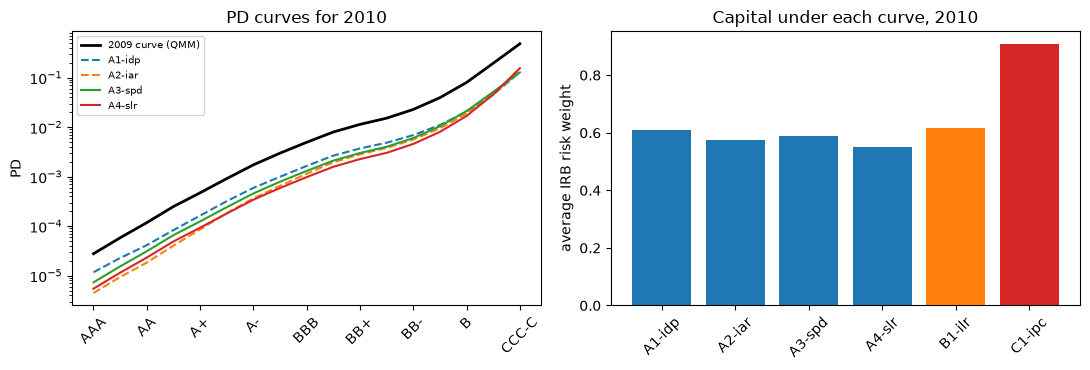

In [10]:
# Draw the PD curves by grade and the risk weights by approach for 2010
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
left.plot(range(len(grades)), curve0, color="black", linewidth=2, label="2009 curve (QMM)")
for key, style in (("A1-idp", "--"), ("A2-iar", "--"), ("A3-spd", "-"), ("A4-slr", "-")):
    left.plot(range(len(grades)), curves[key], style, label=key)
left.set_yscale("log")
left.set_xticks(range(0, len(grades), 2))
left.set_xticklabels(grades[::2], rotation=45)
left.set_ylabel("PD")
left.set_title("PD curves for 2010")
left.legend(fontsize=7)
keys = list(table[2010])
right.bar(range(len(keys)), [table[2010][k] for k in keys], color=["tab:blue"] * 4 + ["tab:orange", "tab:red"])
right.set_xticks(range(len(keys)))
right.set_xticklabels(keys, rotation=45)
right.set_ylabel("average IRB risk weight")
right.set_title("Capital under each curve, 2010")
fig.tight_layout()
plt.show()

## Results

- **The 2009 model is a consistent joint distribution.** The engine reproduces the committed unconditional PD (3.99%), the default profile (to 2e-10) and the accuracy ratio (0.8271) from the profile and the grade default rates. Six of the 17 raw default rates are zero, so a likelihood ratio built on them is undefined and the curve has to be smoothed.
- **QMM.** With alpha = 5.2048 and beta = 2.1613 the smoothed curve hits the 2009 targets and equals the committed curve to 1e-10. It gives AAA 0.0028% where the raw rate is 0, B 8.00% where the raw rate is 9.96%, and is increasing in the grade.
- **Case 1, 2010.** The forecast PD is 1.14%, below the 2009 PD of 3.99%. Scaling the PDs multiplies every grade by c_PD = 0.2642 (the largest scaled PD is 12.8%, proper); the scaled likelihood ratio has c_LR = 1.4081 inside its bracket 0.0188 to 1.5494, with a residual of 0 in equation 4.8a. All four approaches give the forecast PD under the 2010 profile and differ in shape: their accuracy ratios are 0.7935 (invariant default profile), 0.8271 (kept from 2009), 0.8100 (scaled PDs) and 0.8451 (scaled likelihood ratio). Every curve equals the committed one.
- **When less is known.** With only the PD (case 2), the invariant likelihood ratio gives 1.55% under the observed 2010 profile instead of the 1.14% it was given: without the profile it cannot be consistent. Carrying the 2009 curve unchanged (case 3) forecasts 4.32% against an observed 1.14%, 3.8 times.
- **The test of the implied default profile.** In 2010 the invariant default profile (p = 0.046) and the scaled PDs (p = 0.043) are amber and the scaled likelihood ratio (p = 0.112) and the invariant accuracy ratio (p = 0.079) green; in 2011 all nine approaches are green (p from 0.37 to 0.89). The p-values come from 100,000 draws with a Monte Carlo error of about 0.0007.
- **Capital.** The average IRB risk weight of the 2010 portfolio is 55.0% under the scaled likelihood ratio, 57.3% under the invariant accuracy ratio, 58.8% under scaled PDs, 60.9% under the invariant default profile and 90.7% under the unchanged 2009 curve: 64.8% more capital than the scaled likelihood ratio in 2010 and 83.3% in 2011; the four case 1 approaches spread by 10.7% in 2010 and 8.3% in 2011. The recomputation equals the committed impact.
- **Against the print.** The four Table 7 curves are within 0.0005 percentage points of Tasche's printed values in every grade. Table 5's largest gap is 0.0013 points at CCC-C (printed 48.355, recomputed 48.3537; the committed comparison rounds to the printed three decimals and has a gap of 0.001, its tolerance). The committed p-values (4.58, 7.91, 4.25 and 11.15%) sit within about 0.25 points of the printed 4.6, 8.0, 4.0 and 11.3 (their Monte Carlo errors are 0.06 to 0.10 points; the 4.0 against 4.25 for scaled PDs is the widest).

What this notebook does not show: the comparison of all nine approaches on the forecast against the observed PD (notebook 09), or how a calibration error propagates through the IRB formula (notebook 07).

## Summary

- A rating model is a joint distribution of grade and default; the PD curve, the two conditional profiles and the likelihood ratio are equivalent descriptions and the engine checks the identities.
- A curve with zero rates is smoothed by QMM before it is carried to a new year.
- With the forecast profile and PD known, four approaches carry the curve; they differ in what they keep invariant and their curves differ in shape, not in the forecast PD. Scaling the PDs is the simplest and the least defensible.
- Keeping the old curve unchanged forecasts a PD 3.8 times the observed one and costs 65% to 83% more capital than the scaled likelihood ratio.
- The default-profile test sees the shape of a curve, not its level; every recomputation is compared with the committed artifact and with Tasche's printed tables.

**What to try next.** Replace the forecast PD of Step 3 by the 2009 PD and see which approaches keep the curve and which move it; then read notebook 06.

## References

- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), 63-103, equations 3.5, 3.7, 3.8, 4.2 to 4.15 and appendix A, Tables 6 to 8; arXiv 1212.3716. https://doi.org/10.21314/jcr.2013.169
- BCBS, Basel Framework, CRE32, IRB approach: risk-weighted asset calculation (LGD, maturity and PD floor). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Elkan, C. (2001), The foundations of cost-sensitive learning, IJCAI, for the change in base rate (equation 4.11).
- Pearson, K. (1900), On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling, Philosophical Magazine 50(302), 157-175.